# LSTM 预测电池 SOH — MIT 数据集

**特征方案**：V + I + T + dQdV（99分位固定长度，原始时间分辨率）+ 标量特征（dQ1/dQ5/dQ20 + IR + Tavg + chargetime）

**窗口**：5 cycles，stride=3

**预测目标**：容量（-> SOH, RUL）


In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False
import pickle
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from copy import deepcopy
from sklearn.model_selection import train_test_split
from itertools import product


In [2]:
# 加载最终数据
bat_dict = pickle.load(open(r"D:\Python\data_bag\MIT_data\processed\DATA_bat_dict.pkl", "rb"))
print(f"数据加载成功！共 {len(bat_dict)} 个电池")

# 快速查看一个电池的结构
demo = bat_dict["b1c0"]
print(f"示例电池 b1c0:")
print(f"  cycle_life: {demo['cycle_life']}")
print(f"  charge_policy: {demo['charge_policy']}")
print(f"  summary keys: {list(demo['summary'].keys())}")
print(f"  cycles 数量: {len(demo['cycles'])}")
print(f"  QD_fixed 长度: {len(demo['summary']['QD_fixed'])}")


数据加载成功！共 124 个电池
示例电池 b1c0:
  cycle_life: [[1852.]]
  charge_policy: 3.6C(80%)-3.6C
  summary keys: ['IR', 'QC', 'QD', 'Tavg', 'Tmin', 'Tmax', 'chargetime', 'cycle', 'QD_fixed', 'knee_onset', 'knee_point', 'eol_cycle', 'RUL']
  cycles 数量: 1851
  QD_fixed 长度: 1851


放电段长度统计:
  min=104, median=422, mean=385, 99%=458, max=10505


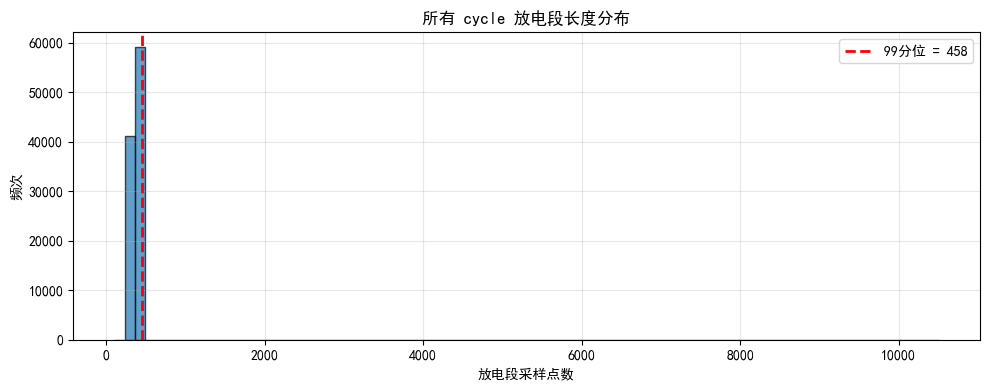

In [ ]:
# ============================================================
# 计算全局 99 分位放电段长度
# ============================================================
all_lengths = []
for name in bat_dict:
    cycles_dict = bat_dict[name]['cycles']
    for cyc_key in cycles_dict:
        cy = cycles_dict[cyc_key]
        I = np.asarray(cy['I'])
        mask = I < -0.01  # 放电段
        n_discharge = mask.sum()
        if n_discharge >= 10:
            all_lengths.append(n_discharge)

all_lengths = np.array(all_lengths)
FIXED_LEN = int(np.percentile(all_lengths, 99))

print(f"放电段长度统计: min={all_lengths.min()}, median={np.median(all_lengths):.0f}, "
      f"mean={all_lengths.mean():.0f}, 99%分位长度={FIXED_LEN}, max={all_lengths.max()}")

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(all_lengths, bins=80, edgecolor='k', alpha=0.7)
ax.axvline(FIXED_LEN, color='r', linestyle='--', linewidth=2,label=f'99分位 = {FIXED_LEN}')
ax.set_xlabel('放电段采样点数')
ax.set_ylabel('频次')
ax.set_title('所有 cycle 放电段长度分布')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [4]:
# ============================================================
# 特征提取函数
#   - 提取放电段 (I < -0.01A) 的 V/I/T
#   - dQdV 已是放电专用（电压网格），直接重采样对齐
#   - 不做 SOC 重采样，保留原始时间分辨率
#   - 短于 FIXED_LEN：尾部 zero-padding
#   - 长于 FIXED_LEN：截断尾部
# ============================================================

def extract_cycle_timeseries(V, I, T, dQdV, fixed_len=FIXED_LEN):
    """从单个 cycle 的放电段提取 V/I/T/dQdV 四通道时间序列。
    V/I/T 用 I < -0.01 提取放电段，dQdV 已是放电专用（电压网格上计算），
    直接重采样到放电段长度。
    - returns: (fixed_len * 4,) float32 array
    """
    mask = I < -0.01
    if mask.sum() < 10:
        mask = np.ones(len(I), dtype=bool)

    V_d = np.asarray(V[mask], dtype=np.float32)
    I_d = np.asarray(I[mask], dtype=np.float32)
    T_d = np.asarray(T[mask], dtype=np.float32)
    n = len(V_d)

    # dQdV 是放电专用的 discharge_dQdV，已在电压网格上计算，长度与 V/I 不同
    # 直接重采样到放电段长度 n，保留 ICA 峰形
    dQdV_raw = np.asarray(dQdV, dtype=np.float32)
    if len(dQdV_raw) > 1:
        grid_old = np.linspace(0, 1, len(dQdV_raw))
        grid_new = np.linspace(0, 1, n)
        dQdV_d = np.interp(grid_new, grid_old, dQdV_raw).astype(np.float32)
    else:
        dQdV_d = np.zeros(n, dtype=np.float32)

    feat = np.zeros(fixed_len * 4, dtype=np.float32)

    if n <= fixed_len:      # 短于 FIXED_LEN：尾部 zero-padding
        feat[0: n] = V_d
        feat[fixed_len: fixed_len+n] = I_d
        feat[2*fixed_len: 2*fixed_len+n] = T_d
        feat[3*fixed_len: 3*fixed_len+n] = dQdV_d
    else:                   # 长于 FIXED_LEN：截断尾部
        feat[0: fixed_len] = V_d[:fixed_len]
        feat[fixed_len: 2*fixed_len] = I_d[:fixed_len]
        feat[2*fixed_len: 3*fixed_len] = T_d[:fixed_len]
        feat[3*fixed_len: 4*fixed_len] = dQdV_d[:fixed_len]

    return feat


def extract_scalar_features(qd_fixed, idx, summary):
    """
    - 提取标量特征：dQ1, dQ5, dQ20, IR, Tavg, chargetime
    - idx: 当前 cycle 在 QD_fixed 数组中的索引
    """
    dq1 = qd_fixed[idx] - qd_fixed[idx - 1] if idx >= 1 else 0.0
    dq5 = qd_fixed[idx] - qd_fixed[idx - 5] if idx >= 5 else 0.0
    dq20 = qd_fixed[idx] - qd_fixed[idx - 20] if idx >= 20 else 0.0

    ir = float(summary['IR'][idx])
    tavg = float(summary['Tavg'][idx])
    chtime = float(summary['chargetime'][idx])

    return np.array([dq1, dq5, dq20, ir, tavg, chtime], dtype=np.float32)


FEAT_DIM_TS = FIXED_LEN * 4       # 时序特征维度 (V+I+dQdV+T)
FEAT_DIM_SCALAR = 6               # 标量特征维度（dQ1/dQ5/dQ20/IR/Tavg/chargetime）
FEAT_DIM = FEAT_DIM_TS + FEAT_DIM_SCALAR  # 总特征维度
print(f"特征维度: 时序{FEAT_DIM_TS} ({FIXED_LEN}x4) + 标量{FEAT_DIM_SCALAR} = 总计 {FEAT_DIM}")
print(f"  时序特征: V/I/T/dQdV, 各自长度={FIXED_LEN}")
print(f"  标量特征: dQ1/dQ5/dQ20/IR/Tavg/chargetime, 共 {FEAT_DIM_SCALAR} 个")

特征维度: 时序1832 (458x4) + 标量6 = 总计 1838
  时序特征: V/I/T/dQdV, 各自长度=458
  标量特征: dQ1/dQ5/dQ20/IR/Tavg/chargetime, 共 6 个


In [5]:
# ============================================================
# 数据集构建：缓存 + 滑动窗口 + 训练/验证/测试划分
# ============================================================

def build_lstm_dataset(
    bat_dict,
    window_size=5,
    stride=3,
    train_ratio=0.70,
    val_ratio=0.15,
    test_ratio=0.15,
    seed=42,
    verbose=True,
):
    """构建 LSTM 容量预测数据集。

    流程：
    1. 按 cycle_life 三分位分层划分电池级 70/15/15
    2. 每个 cycle 提取 V/I/dQdV/T 时序 + 标量特征，缓存为数组
    3. 滑动窗口 (window_size, stride) 生成样本索引
    4. Z-score 归一化（训练集统计量）

    Returns:
        datasets: 归一化的{'train': (samples, y_dict), 'val': ..., 'test': ...}，其中samples 为 [(name, w)]，y_dict 为 {capacity列表}
        bat_features: {name: [(n_cycles, FEAT_DIM)]}
        bat_meta: {name: {qd_fixed, cycle_nums, valid_indices}}
        meta: {train_names, window_size, feat_dim, norm params, ...}
    """

    # ---------- 1. 电池级分层划分 ----------
    all_names = sorted(bat_dict.keys())
    cycle_lifes = np.array([float(np.asarray(bat_dict[n]['cycle_life']).ravel()[0]) for n in all_names])    # 展平为一维数组

    # cycle_life 三分位分层（与现有 BiLSTM/Transformer 对齐）
    tertile_edges = np.quantile(cycle_lifes, [0, 1/3, 2/3, 1])
    tertile_edges[0] -= 1
    tertile_edges[-1] += 1
    cycle_bins = np.digitize(cycle_lifes, tertile_edges[1:-1])  # cycle_bins返回值: 0/1/2 对应三分位分组

    if verbose:
        for b in range(3):
            mask = cycle_bins == b  # mask 为 bool 数组，True 表示属于分组 b
            lo, hi = cycle_lifes[mask].min(), cycle_lifes[mask].max()
            print(f"  寿命分组 {b}: {mask.sum()} 电池, 范围 [{lo:.0f}, {hi:.0f}]")
        print()

    names_temp, names_test = train_test_split(all_names, test_size=test_ratio, random_state=seed, stratify=cycle_bins)
    val_adj = val_ratio / (train_ratio + val_ratio)
    temp_bins = cycle_bins[[all_names.index(n) for n in names_temp]]
    names_train, names_val = train_test_split(names_temp, test_size=val_adj, random_state=seed, stratify=temp_bins)

    if verbose:
        print(f"数据集划分: train={len(names_train)}, val={len(names_val)}, test={len(names_test)}\n")

    # ---------- 2. 特征缓存 + 滑动窗口 ----------
    bat_features = {}
    bat_meta = {}

    def _build_cache_and_samples(name_list):
        """
        缓存所有电池的 cycle 特征，并生成滑动窗口样本
        Args:
            name_list: 电池名称列表
        Returns:
            samples: 样本索引列表 [(name, w)]
            y_dict: 字典 {capacity列表}
        """
        samples = []
        y_cap = []

        for name in name_list:
            b = bat_dict[name]
            cycles_dict = b['cycles']   # 细点
            summary = b['summary']      # 粗点
            qd_fixed = np.asarray(summary['QD_fixed'], dtype=np.float64)
            cycle_nums = np.asarray(summary['cycle'], dtype=np.int64)

            # 在 “粗点” 中 找到同时存在于 cycles dict（细点） 和 QD_fixed（粗点） 的有效索引
            valid_indices = [
                i for i, cn in enumerate(cycle_nums)
                if str(int(cn)) in cycles_dict and i < len(qd_fixed)
            ]
            n_valid = len(valid_indices)    # 每个粗点中的有效细点数量
            if n_valid < window_size:
                continue

            # 每个 cycle 提取一次特征
            cached = np.empty((n_valid, FEAT_DIM), dtype=np.float32)
            for slot, idx in enumerate(valid_indices):
                cy = cycles_dict[str(int(cycle_nums[idx]))]
                ts_feat = extract_cycle_timeseries(
                    cy['V'], cy['I'], cy['T'], cy['dQdV'])      # 时序特征
                scalar_feat = extract_scalar_features(qd_fixed, idx, summary)   # 标量特征
                cached[slot] = np.concatenate([ts_feat, scalar_feat])       # 总特征 = 时序 + 标量

            bat_features[name] = cached         #  (n_cycles, FEAT_DIM)
            bat_meta[name] = {
                'qd_fixed':     qd_fixed,
                'cycle_nums':   cycle_nums,
                'valid_indices': valid_indices,
            }

            # 滑动窗口
            n_windows = n_valid - window_size + 1
            for w in range(0, n_windows, stride):
                last_idx = valid_indices[w + window_size - 1]
                samples.append((name, w))
                y_cap.append(qd_fixed[last_idx])

        y_dict = {
            'capacity': np.array(y_cap, dtype=np.float32),
        }
        return samples, y_dict

    if verbose:
        print(f"构建训练集...")
    s_train, y_train = _build_cache_and_samples(names_train)
    if verbose:
        print(f"  train: {len(s_train)} 窗口")

    if verbose:
        print("构建验证集...")
    s_val, y_val = _build_cache_and_samples(names_val)
    if verbose:
        print(f"  val: {len(s_val)} 窗口")

    if verbose:
        print("构建测试集...")
    s_test, y_test = _build_cache_and_samples(names_test)
    if verbose:
        print(f"  test: {len(s_test)} 窗口")

    total_cycles = sum(v.shape[0] for v in bat_features.values())
    print(f"  特征缓存: {len(bat_features)} 电池, {total_cycles} 周期, "
          f"{total_cycles * FEAT_DIM * 4 / 1024**2:.0f} MiB")

    # ---------- 3. Z-score 归一化（训练集统计量）----------
    # 增量计算 mean
    n_elems, sum_f = 0, np.zeros(FEAT_DIM, dtype=np.float64)
    for name in names_train:
        if name in bat_features:
            f = bat_features[name]
            sum_f += f.sum(axis=0)
            n_elems += f.shape[0]
    feat_mean = (sum_f / n_elems).astype(np.float32)

    # 增量计算 std
    sum_sq = np.zeros(FEAT_DIM, dtype=np.float64)
    for name in names_train:
        if name in bat_features:
            sum_sq += ((bat_features[name] - feat_mean) ** 2).sum(axis=0)
    feat_std = np.sqrt(sum_sq / n_elems).astype(np.float32) + 1e-8

    # 原地归一化
    for feats in bat_features.values():
        feats -= feat_mean
        feats /= feat_std

    # 标签归一化
    cap_mean = y_train['capacity'].mean()
    cap_std  = y_train['capacity'].std() + 1e-8

    for yd in [y_train, y_val, y_test]:
        yd['capacity_norm'] = (yd['capacity'] - cap_mean) / cap_std

    datasets = {
        'train': (s_train, y_train),
        'val':   (s_val,   y_val),
        'test':  (s_test,  y_test),
    }

    meta = {
        'train_names': names_train,
        'val_names':   names_val,
        'test_names':  names_test,
        'feat_mean':   feat_mean,
        'feat_std':    feat_std,
        'cap_mean':    cap_mean,
        'cap_std':     cap_std,
        'window_size': window_size,
        'stride':      stride,
        'fixed_len':   FIXED_LEN,
        'feat_dim_ts': FEAT_DIM_TS,
        'feat_dim_scalar': FEAT_DIM_SCALAR,
        'feat_dim':    FEAT_DIM,
    }

    if verbose:
        print(f"\n数据准备完成")
        print(f"  输入形状: ({window_size}, {FEAT_DIM})  (window_size x feat_dim)")
        print(f"  容量归一化: mean={cap_mean:.3f}, std={cap_std:.3f}")

    return datasets, bat_features, bat_meta, meta


# ---------- 执行 ----------
datasets, bat_features, bat_meta, meta = build_lstm_dataset(
    bat_dict,
    window_size=5,
    stride=3,
    train_ratio=0.70,
    val_ratio=0.15,
    test_ratio=0.15,
    seed=42,
)

(s_train, y_train) = datasets['train']
(s_val,   y_val)   = datasets['val']
(s_test,  y_test)  = datasets['test']

print(f"\n最终数据统计:")
print(f"  train: {len(s_train)} 窗口, val: {len(s_val)} 窗口, test: {len(s_test)} 窗口")
print(f"  容量范围: train [{y_train['capacity'].min():.3f}, {y_train['capacity'].max():.3f}]")

  寿命分组 0: 41 电池, 范围 [148, 534]
  寿命分组 1: 41 电池, 范围 [535, 860]
  寿命分组 2: 42 电池, 范围 [862, 2237]

数据集划分: train=86, val=19, test=19

构建训练集...
  train: 23077 窗口
构建验证集...
  val: 5341 窗口
构建测试集...
  test: 4917 窗口
  特征缓存: 124 电池, 100377 周期, 704 MiB

数据准备完成
  输入形状: (5, 1838)  (window_size x feat_dim)
  容量归一化: mean=1.032, std=0.052

最终数据统计:
  train: 23077 窗口, val: 5341 窗口, test: 4917 窗口
  容量范围: train [0.827, 1.098]


In [ ]:
# ============================================================
# 模型定义
# ============================================================
# BiLSTM            — BiLSTM + Attention Pooling（基准）
# CNN_BiLSTM_ECA    — CNN(2D) + BiLSTM + ECA + Attention Pooling
# CNN_BiLSTM        — CNN(2D 单层) + BiLSTM + Attention Pooling（对照）
# BiLSTM_MoE        — BiLSTM + MoE（稀疏专家）+ Attention Pooling（增强）
# 四个模型均为单头：共享编码器 + cap_head(容量)
# ============================================================

from st_moe_pytorch import MoE          # 参考代码/MoE.ipynb

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"使用设备: {device}")


class BatteryDataset(Dataset):
    """懒加载 Dataset：从缓存中按窗口索引取数据（容量单标签）"""

    def __init__(self, samples, y_dict, bat_features, window_size,
                 cap_mean=None, cap_std=None):
        self.samples = samples
        self.bat_features = bat_features
        self.window_size = window_size
        self.capacity = torch.from_numpy(y_dict['capacity'])

        self.cap_mean = torch.tensor(cap_mean) if cap_mean is not None else self.capacity.float().mean()
        self.cap_std  = torch.tensor(cap_std)  if cap_std  is not None else self.capacity.float().std() + 1e-8

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        name, w = self.samples[idx]
        X = torch.from_numpy(self.bat_features[name][w:w + self.window_size])   # bat_features: {name: [(n_cycles, FEAT_DIM)]}
        cap_norm = (self.capacity[idx] - self.cap_mean) / self.cap_std
        return X, cap_norm          # X (window_size, FEAT_DIM)


# ============================================================
# BiLSTM + Attention Pooling（基准模型）
# ============================================================

class BiLSTM(nn.Module):
    """BiLSTM + Attention Pooling

    架构：
      Input Projection (1838→256) → BiLSTM(2层, bidirectional)
      → Attention Pooling（学习 window_size 个时间步的权重）
      → Shared MLP(→64, ReLU, Dropout)
      → cap_head(64→1) 输出（容量）

    Args:
        input_dim:   输入维度 (FEAT_DIM = 1838)
        hidden_dim:  BiLSTM 隐层维度 (默认 128)
        num_layers:  BiLSTM 层数 (默认 2)
        dropout:     Dropout 比率 (默认 0.1)
        scalar_dim:  接口兼容参数（BiLSTM 不使用；CNN_BiLSTM_ECA 拆分时序/标量用）
        window_size: 接口兼容参数（BiLSTM 天然支持任意 T；CNN_BiLSTM_ECA 按窗口池化）
    """

    def __init__(self, input_dim, hidden_dim=128, num_layers=2, dropout=0.1,
                 scalar_dim=None, window_size=5):
        super().__init__()

        # ── 输入投影：1838 → hidden_dim*2，稳定高维输入 ──
        proj_dim = hidden_dim * 2
        self.input_proj = nn.Sequential(
            nn.Linear(input_dim, proj_dim),
            nn.LayerNorm(proj_dim),
            nn.ReLU(),
            nn.Dropout(dropout * 0.5),
        )

        self.lstm = nn.LSTM(
            proj_dim, hidden_dim, num_layers,
            batch_first=True, bidirectional=True, dropout=dropout,
        )
        out_dim = hidden_dim * 2

        # Attention pooling（学习每个时间步的重要性）
        self.attn = nn.Linear(out_dim, 1)

        # 共享层
        self.shared = nn.Sequential(
            nn.Linear(out_dim, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
        )

        self.cap_head = nn.Linear(64, 1)

    def forward(self, x):
        x = self.input_proj(x)                               # (B, T, 1838) → (B, T, proj_dim)      T是窗口大小
        lstm_out, _ = self.lstm(x)                           # (B, T, hidden*2)                     
        attn_weights = torch.softmax(self.attn(lstm_out), dim=1)  # (B, T, 1)
        pooled = (attn_weights * lstm_out).sum(dim=1)        # (B, hidden*2)
        shared = self.shared(pooled)                         # (B, 64)
        cap_pred = self.cap_head(shared).squeeze(-1)         # (B,)
        return cap_pred


# ============================================================
# ECAAttention（ECA 通道注意力模块）
# ============================================================

class ECAAttention(nn.Module):
    """ECA 通道注意力模块。

    对 BiLSTM 输出的通道维做自适应卷积注意力，
    让模型自动学习哪些特征通道对容量预测更重要。

    Args:
        channels: 通道数（= hidden_dim * 2）
        kernel_size: 1D 卷积核大小，默认 None 则自适应计算
    """

    def __init__(self, channels, kernel_size=None):
        super().__init__()
        if kernel_size is None:
            import math
            kernel_size = int(abs(math.log2(channels) / 2 + 0.5))
            if kernel_size % 2 == 0:
                kernel_size += 1
        self.gap = nn.AdaptiveAvgPool1d(1)  # 全局平均池化，输出长度固定为 1 ：(B, C, T) → (B, C, 1)      C是通道数
        self.conv = nn.Conv1d(1, 1, kernel_size=kernel_size,
                              padding=kernel_size // 2, bias=False)     # 输入、输出通道 1
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        # x: (B, T, C)    批大小，时间步，通道数
        y = self.gap(x.transpose(1, 2))        # (B, C, 1)
        y = y.squeeze(-1).unsqueeze(1)          # (B, 1, C)         输入要求(B, input_channels, length)
        y = self.conv(y)                        # (B, 1, C)         1D卷积
        y = self.sigmoid(y)                     # (B, 1, C)         各通道注意力权重
        return x * y                             # (B, T, C) * (B, 1, C)        将权重乘回特征


# ============================================================
# CNN(2D) + BiLSTM + ECA + Attention Pooling（增强模型）
# ============================================================

class CNN_BiLSTM_ECA(nn.Module):
    """CNN(2D) + BiLSTM + ECA + Attention Pooling

    各组件分工：
      CNN(2D)      — Conv2d 同时在 cycle 方向和采样点方向卷积，
                      底层就能捕获相邻 cycle 之间的 dQdV 峰位移、
                      电压平台斜率变化等退化信号
      BiLSTM       — 进一步建模跨 window_size 个 cycle 的特征时间演变
      ECA          — 通道注意力，强化对容量敏感的特征维度
      Attention    — 时间注意力，学习 window_size 个时间步中哪个最关键
      Shared MLP   — 容量回归

    CNN 2D vs 1D 的关键区别：
      1D: 每个 cycle 独立过 Conv1d，跨 cycle 信息全靠 BiLSTM 上层融合
      2D: kernel=(3,7) 覆盖相邻 3 个 cycle × 7 个采样点
          CNN 底层特征就包含"cycle N vs cycle N+1"的形态对比

    Args:
        input_dim:   输入总维度 (FEAT_DIM = 1838)
        hidden_dim:  BiLSTM 隐层维度 (默认 128)
        num_layers:  BiLSTM 层数 (默认 2)
        dropout:     Dropout 比率 (默认 0.1)
        ts_dim:      时序特征维度 (默认从 input_dim 推算: input_dim - scalar_dim)
        fixed_len:   放电段采样点数 (默认从 ts_dim 推算: ts_dim // 4)
        scalar_dim:  标量特征维度 (默认 6)
        window_size: 窗口内 cycle 数（CNN 保留的时间步数，默认 5）
    """

    def __init__(self, input_dim, hidden_dim=128, num_layers=2, dropout=0.1,
                 ts_dim=None, fixed_len=None, scalar_dim=6, window_size=5):
        super().__init__()

        if scalar_dim is None:
            scalar_dim = 6
        if ts_dim is None:
            ts_dim = input_dim - scalar_dim          # 时序特征维
        if fixed_len is None:
            fixed_len = ts_dim // 4                  # 458

        self.ts_dim = ts_dim
        self.fixed_len = fixed_len
        self.scalar_dim = scalar_dim
        self.num_steps = window_size        # 时间步数（= 窗口内 cycle 数）

        # ── 2D CNN：在 (window_size cycles × 458 采样点) 的 2D 网格上卷积 ──
        # 输入: (B, 4, window_size, 458) — 4 通道 (V/I/T/dQdV) 作为 Conv2d 输入通道
        # kernel=(3,7): 视野 = 相邻 3 cycle × 7 采样点
        # stride=(1,2): cycle 维不压缩 (后续 BiLSTM 需要 window_size 步)，
        #               采样点维逐步下采样 458→229→115→58→1
        self.cnn2d = nn.Sequential(
            # (B, 4, window_size, 458) → (B, 32, window_size, 229)
            nn.Conv2d(4, 32, kernel_size=(3, 7), stride=(1, 2), padding=(1, 3)),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            # (B, 32, window_size, 229) → (B, 64, window_size, 115)
            nn.Conv2d(32, 64, kernel_size=(3, 5), stride=(1, 2), padding=(1, 2)),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            # (B, 64, window_size, 115) → (B, 128, window_size, 58)
            nn.Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 2), padding=(1, 1)),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            # 保留 cycle 维度 (window_size)，采样点维从 58 pool 到 1 → (B, 128, window_size, 1)
            nn.AdaptiveAvgPool2d((self.num_steps, 1)),
        )
        cnn_dim = 128

        # ── BiLSTM ──
        lstm_input_dim = cnn_dim + scalar_dim        # 128 + scalar_dim
        self.lstm = nn.LSTM(
            lstm_input_dim, hidden_dim, num_layers,
            batch_first=True, bidirectional=True, dropout=dropout,
        )
        out_dim = hidden_dim * 2

        # ── ECA 通道注意力 ──
        self.eca = ECAAttention(out_dim)

        # ── Attention Pooling（时间注意力）──
        self.attn = nn.Linear(out_dim, 1)

        # ── 共享层 ──
        self.shared = nn.Sequential(
            nn.Linear(out_dim, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
        )

        self.cap_head = nn.Linear(64, 1)

    def forward(self, x):
        B, T, D = x.shape

        # ── 拆分为时序 + 标量 ──
        x_ts = x[:, :, :self.ts_dim]                    # (B, T, 1832)
        x_scalar = x[:, :, self.ts_dim:]                 # (B, T, scalar_dim)

        # ── 2D CNN：(B, T, 4, 458) → permute → (B, 4, T, 458) ──
        x_ts = x_ts.reshape(B, T, 4, self.fixed_len)     # (B, T, 4, 458)
        x_ts = x_ts.permute(0, 2, 1, 3)                  # (B, 4, T, 458)
        x_cnn = self.cnn2d(x_ts)                         # (B, 128, T, 1)
        x_cnn = x_cnn.squeeze(-1).permute(0, 2, 1)       # (B, T, 128)

        # ── 拼接 CNN 特征 + 标量特征 ──
        x_combined = torch.cat([x_cnn, x_scalar], dim=-1)  # (B, T, cnn_dim+scalar_dim)

        # ── BiLSTM ──
        lstm_out, _ = self.lstm(x_combined)         # (B, T, hidden*2)

        # ── ECA 通道注意力 ──
        lstm_out = self.eca(lstm_out)               # (B, T, hidden*2)

        # ── Attention Pooling（时间维度）──
        attn_weights = torch.softmax(self.attn(lstm_out), dim=1)  # (B, T, 1)
        pooled = (attn_weights * lstm_out).sum(dim=1)             # (B, hidden*2)

        # ── 容量回归 ──
        shared = self.shared(pooled)                 # (B, 64)
        cap_pred = self.cap_head(shared).squeeze(-1)  # (B,)
        return cap_pred


# ============================================================
# CNN(2D) + BiLSTM + Attention Pooling
# ============================================================

class CNN_BiLSTM(nn.Module):
    """2D CNN（单层、少量卷积核）+ BiLSTM，无 ECA。
    与 CNN_BiLSTM_ECA 的区别：
      - 去掉 ECA 通道注意力
      - CNN 层数改为 1 层，卷积核数量降到 cnn_channels（默认 16）
    若想改 2 层：取消 cnn2d 中被注释的第二层卷积，并把 cnn_dim 改为 cnn_channels * 2。
    """
    def __init__(self, input_dim, hidden_dim=128, num_layers=2, dropout=0.1,
                 ts_dim=None, fixed_len=None, scalar_dim=6, window_size=5,
                 cnn_channels=16):
        super().__init__()

        if scalar_dim is None:
            scalar_dim = 6
        if ts_dim is None:
            ts_dim = input_dim - scalar_dim          # 时序特征维
        if fixed_len is None:
            fixed_len = ts_dim // 4                  # 458

        self.ts_dim = ts_dim
        self.fixed_len = fixed_len
        self.scalar_dim = scalar_dim
        self.num_steps = window_size

        # ---- 2D CNN：单层，核数量降到 cnn_channels ----
        # cycle 轴(5) stride=1 不压缩；曲线轴 458 -> 229 (stride 2) -> pool 到 1
        self.cnn2d = nn.Sequential(
            nn.Conv2d(4, cnn_channels, kernel_size=(3, 7), stride=(1, 2), padding=(1, 3)),
            nn.BatchNorm2d(cnn_channels),
            nn.ReLU(),
            # ---- 改 2 层：取消注释下面三行，并把下方 cnn_dim 改为 cnn_channels*2 ----
            # nn.Conv2d(cnn_channels, cnn_channels * 2, kernel_size=(3, 5),
            #           stride=(1, 2), padding=(1, 2)),
            # nn.BatchNorm2d(cnn_channels * 2),
            # nn.ReLU(),
            nn.AdaptiveAvgPool2d((self.num_steps, 1)),
        )
        cnn_dim = cnn_channels

        # ---- BiLSTM ----
        lstm_input_dim = cnn_dim + scalar_dim        # cnn_dim + scalar_dim
        self.lstm = nn.LSTM(
            lstm_input_dim, hidden_dim, num_layers,
            batch_first=True, bidirectional=True, dropout=dropout,
        )
        out_dim = hidden_dim * 2

        # ---- Attention Pooling（时间注意力）----
        self.attn = nn.Linear(out_dim, 1)

        # ---- 共享层 ----
        self.shared = nn.Sequential(
            nn.Linear(out_dim, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
        )

        self.cap_head = nn.Linear(64, 1)

    def forward(self, x):
        B, T, D = x.shape

        # ---- 拆分为时序 + 标量 ----
        x_ts = x[:, :, :self.ts_dim]                    # (B, T, 1832)
        x_scalar = x[:, :, self.ts_dim:]                 # (B, T, scalar_dim)

        # ---- 2D CNN：(B, T, 4, 458) -> permute -> (B, 4, T, 458) ----
        x_ts = x_ts.reshape(B, T, 4, self.fixed_len)     # (B, T, 4, 458)
        x_ts = x_ts.permute(0, 2, 1, 3)                  # (B, 4, T, 458)
        x_cnn = self.cnn2d(x_ts)                         # (B, cnn_dim, T, 1)
        x_cnn = x_cnn.squeeze(-1).permute(0, 2, 1)       # (B, T, cnn_dim)

        # ---- 拼接 CNN 特征 + 标量特征 ----
        x_combined = torch.cat([x_cnn, x_scalar], dim=-1)  # (B, T, cnn_dim+scalar_dim)

        # ---- BiLSTM（无 ECA）----
        lstm_out, _ = self.lstm(x_combined)         # (B, T, hidden*2)

        # ---- Attention Pooling（时间维度）----
        attn_weights = torch.softmax(self.attn(lstm_out), dim=1)  # (B, T, 1)
        pooled = (attn_weights * lstm_out).sum(dim=1)             # (B, hidden*2)

        # ---- 容量回归 ----
        shared = self.shared(pooled)                 # (B, 64)
        cap_pred = self.cap_head(shared).squeeze(-1)  # (B,)
        return cap_pred


# ============================================================
# BiLSTM + MoE（Mixture of Experts）+ Attention Pooling（增强模型）
# ============================================================

class BiLSTM_MoE(nn.Module):
    """BiLSTM + MoE + Attention Pooling

    在基准 BiLSTM 之上，把 LSTM 输出的每个 cycle 隐状态送入 MoE：
      - N 个结构相同的专家 FFN + top-2 路由器（st_moe_pytorch，参考代码/MoE.ipynb）
      - 每个 cycle token 只激活 top-2 专家：参数量 ×N，但单 token
        计算量仅 ×top_n（稀疏激活）
      - 路由器学习"不同老化阶段 / 充电策略 → 不同专家"，比单一 FFN
        更能覆盖多模态老化路径
      - 额外引入专家负载均衡损失 + router z-loss（辅助损失），
        训练时加进总损失（cell 7 run_epoch 已支持 aux_weight）

    与 BiLSTM 的差异：
      - lstm_out (B, T, hidden*2) 后插入 LayerNorm + MoE + 残差连接
      - forward 额外记录 self.last_aux_loss（供 run_epoch 加权；eval 时忽略）
      - 评估时库内部自动切换 threshold_eval / capacity_factor_eval

    Args:
        input_dim:   输入维度 (FEAT_DIM = 1838)
        hidden_dim:  BiLSTM 隐层维度 (默认 128)
        num_layers:  BiLSTM 层数 (默认 2)
        dropout:     Dropout 比率 (默认 0.1)
        scalar_dim / window_size: 接口兼容参数（BiLSTM 同款，不使用）
        num_experts:        专家个数（默认 8）
        expert_hidden_mult: 单专家 FFN 隐藏层 = dim × mult（默认 2）
        gating_top_n:       每 token 激活专家数（默认 2）
        threshold_train / threshold_eval: 路由接受阈值（训练/推理）
        capacity_factor_train / capacity_factor_eval: 专家容量因子（推理放宽不丢 token）
        balance_loss_coef / router_z_loss_coef: 辅助损失权重（库内已加权）
    """

    def __init__(self, input_dim, hidden_dim=128, num_layers=2, dropout=0.1,
                 scalar_dim=None, window_size=5,
                 num_experts=8, expert_hidden_mult=2, gating_top_n=2,
                 threshold_train=0.2, threshold_eval=0.2,
                 capacity_factor_train=1.25, capacity_factor_eval=2.0,
                 balance_loss_coef=1e-2, router_z_loss_coef=1e-3):
        super().__init__()

        # ── 输入投影：1838 → hidden_dim*2（与 BiLSTM 完全一致）──
        proj_dim = hidden_dim * 2
        self.input_proj = nn.Sequential(
            nn.Linear(input_dim, proj_dim),
            nn.LayerNorm(proj_dim),
            nn.ReLU(),
            nn.Dropout(dropout * 0.5),
        )

        self.lstm = nn.LSTM(
            proj_dim, hidden_dim, num_layers,
            batch_first=True, bidirectional=True, dropout=dropout,
        )
        out_dim = hidden_dim * 2

        # ── MoE（稀疏专家，作用于每个 cycle token）──
        # dim = LSTM 输出维度 (hidden*2)，与 BiLSTM 接口一致
        self.moe_norm = nn.LayerNorm(out_dim)      # PreNorm：路由/专家对输入尺度敏感
        self.moe = MoE(
            dim=out_dim,
            num_experts=num_experts,
            expert_hidden_mult=expert_hidden_mult,
            gating_top_n=gating_top_n,
            threshold_train=threshold_train,
            threshold_eval=threshold_eval,
            capacity_factor_train=capacity_factor_train,
            capacity_factor_eval=capacity_factor_eval,
            balance_loss_coef=balance_loss_coef,
            router_z_loss_coef=router_z_loss_coef,
        )

        # ── 与 BiLSTM 相同的预测头 ──
        self.attn = nn.Linear(out_dim, 1)

        self.shared = nn.Sequential(
            nn.Linear(out_dim, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
        )

        self.cap_head = nn.Linear(64, 1)

    def forward(self, x):
        x = self.input_proj(x)                                    # (B, T, 1838) → (B, T, hidden*2)
        lstm_out, _ = self.lstm(x)                                # (B, T, hidden*2)

        # MoE：每个 cycle token 独立路由到 top-2 专家 + 残差连接
        moe_result = self.moe(self.moe_norm(lstm_out))            # (B, T, hidden*2)
        self.last_aux_loss = moe_result.total_aux_loss            # 供 run_epoch 加权
        lstm_out = lstm_out + moe_result.outputs                  # 残差

        attn_weights = torch.softmax(self.attn(lstm_out), dim=1)  # (B, T, 1)
        pooled = (attn_weights * lstm_out).sum(dim=1)             # (B, hidden*2)
        shared = self.shared(pooled)                              # (B, 64)
        cap_pred = self.cap_head(shared).squeeze(-1)              # (B,)
        return cap_pred


# ---- BiLSTM_MoE 形状 + 参数量测试 ----
print("\n=== BiLSTM_MoE 形状测试 ===")
_test_moe = BiLSTM_MoE(
    input_dim=1838, hidden_dim=64, num_layers=2, dropout=0.1,
    scalar_dim=6, window_size=5, num_experts=8, expert_hidden_mult=2,
).to(device)
_x_test = torch.randn(4, 5, 1838).to(device)
_test_moe.train()
_pred = _test_moe(_x_test)
print(f"输入 X:     {tuple(_x_test.shape)}")
print(f"输出 pred:  {tuple(_pred.shape)}")
print(f"aux_loss:   {_test_moe.last_aux_loss.item():.4f}  (训练时加进总损失)")
_n_base = sum(p.numel() for p in _test_moe.input_proj.parameters()) \
        + sum(p.numel() for p in _test_moe.lstm.parameters()) \
        + sum(p.numel() for p in _test_moe.attn.parameters()) \
        + sum(p.numel() for p in _test_moe.shared.parameters()) \
        + sum(p.numel() for p in _test_moe.cap_head.parameters())
_n_moe = sum(p.numel() for p in _test_moe.moe.parameters())
print(f"参数量: BiLSTM 主干 {_n_base:,} + MoE {_n_moe:,} = 总计 {_n_base + _n_moe:,}")
_test_moe.eval()
with torch.no_grad():
    _pred_eval = _test_moe(_x_test)
print(f"eval 模式输出: {tuple(_pred_eval.shape)}  (predict_battery 路径兼容)")
del _test_moe, _x_test, _pred, _pred_eval
torch.cuda.empty_cache()

print("\n模型定义完成")
print(f"  BiLSTM          — BiLSTM + Attention Pooling（基准）")
print(f"  CNN_BiLSTM_ECA  — CNN(2D) + BiLSTM + ECA + Attention Pooling")
print(f"  CNN_BiLSTM      — CNN(2D 单层) + BiLSTM + Attention Pooling（对照）")
print(f"  BiLSTM_MoE      — BiLSTM + MoE（稀疏专家）+ Attention Pooling（增强）")

使用设备: cuda

=== BiLSTM_MoE 形状测试 ===
输入 X:     (4, 5, 1838)
输出 pred:  (4,)
aux_loss:   0.0190  (训练时加进总损失)
参数量: BiLSTM 主干 442,754 + MoE 528,368 = 总计 971,122
eval 模式输出: (4,)  (predict_battery 路径兼容)

模型定义完成
  BiLSTM          — BiLSTM + Attention Pooling（基准）
  CNN_BiLSTM_ECA  — CNN(2D) + BiLSTM + ECA + Attention Pooling
  CNN_BiLSTM      — CNN(2D 单层) + BiLSTM + Attention Pooling（对照）
  BiLSTM_MoE      — BiLSTM + MoE（稀疏专家）+ Attention Pooling（增强）


In [7]:
# ============================================================
# 训练工具函数 + Dataset 构建
# ============================================================

ws = meta['window_size']

# 构建 Dataset（训练集自算统计量，val/test 使用训练集统计量）
train_set = BatteryDataset(s_train, y_train, bat_features, ws)
cap_mean_np = train_set.cap_mean.item()
cap_std_np  = train_set.cap_std.item()
val_set  = BatteryDataset(s_val,  y_val,  bat_features, ws,
                          cap_mean_np, cap_std_np)
test_set = BatteryDataset(s_test, y_test, bat_features, ws,
                          cap_mean_np, cap_std_np)

print(f"Dataset 构建完成: train={len(train_set)}, val={len(val_set)}, test={len(test_set)}")
print(f"容量归一化: mean={cap_mean_np:.3f}, std={cap_std_np:.3f}")


def run_epoch(model, loader, optimizer, loss_fn, device,
              training=True, max_norm=1.0, aux_weight=1.0):
    """训练/验证一个 epoch（容量损失 MSE + MoE 辅助损失）"""
    if training:
        model.train()
    else:
        model.eval()

    total_loss, n = 0.0, 0
    for X_b, cap_tgt in loader:
        X_b = X_b.to(device)
        cap_tgt = cap_tgt.to(device)
        cap_pred = model(X_b)
        loss = loss_fn(cap_pred, cap_tgt)
        # MoE 辅助损失（BiLSTM_MoE 等）：仅训练时加权进 loss，val 保持纯 MSE
        aux = getattr(model, 'last_aux_loss', None)
        if training and aux is not None:
            loss = loss + aux_weight * aux

        if training:
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm)
            optimizer.step()

        total_loss += loss.item() * len(X_b)
        n += len(X_b)
    return total_loss / n


def train_model(model, train_set, val_set, device,
                epochs=1000, batch_size=128, lr=1e-3,
                patience=50, verbose=True): 
    """训练模型，返回最佳状态和训练历史"""
    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
    val_loader   = DataLoader(val_set,   batch_size=batch_size, shuffle=False)

    loss_fn = nn.MSELoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=5e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=8)

    best_state = deepcopy(model.state_dict())
    best_val, stale = float('inf'), 0
    history = {'train': [], 'val': []}

    for ep in range(epochs):
        tr_loss = run_epoch(model, train_loader, optimizer, loss_fn,
                            device, training=True)
        vl_loss = run_epoch(model, val_loader, optimizer, loss_fn,
                            device, training=False)
        scheduler.step(vl_loss)
        history['train'].append(tr_loss)
        history['val'].append(vl_loss)

        if vl_loss < best_val:
            best_val = vl_loss
            best_state = deepcopy(model.state_dict())
            stale = 0
        else:
            stale += 1

        if verbose and (ep % 10 == 0 or ep == epochs - 1):
            print(f"  Epoch {ep+1:3d}/{epochs}  tr={tr_loss:.4f}  vl={vl_loss:.4f}  "
                  f"lr={optimizer.param_groups[0]['lr']:.1e}")

        if stale >= patience:
            if verbose:
                print(f"  早停于 epoch {ep+1}")
            break

    model.load_state_dict(best_state)
    return model, history

Dataset 构建完成: train=23077, val=5341, test=4917
容量归一化: mean=1.032, std=0.052


In [8]:
import random
np.random.seed(1)
random.seed(1)
torch.manual_seed(1)
torch.cuda.manual_seed(1)

In [11]:
# ============================================================
# 网格搜索超参寻优: lr x hidden_dim x num_layers x dropout x batch_size x num_experts
#   - 目标 = min val_loss（归一化容量 MSE）
#   - 切换模型：把下面 BiLSTM_MoE(...) 换成 BiLSTM(...) / CNN_BiLSTM_ECA(...) / CNN_BiLSTM(...)
#   ⚠️ num_experts / expert_hidden_mult 仅 BiLSTM_MoE 支持：
#      切回 BiLSTM / CNN_BiLSTM_ECA / CNN_BiLSTM 时，需同步删掉
#      "网格循环" 和 "加载最佳模型" 两处的这两行，否则 TypeError。
# ============================================================
from itertools import product

lr_list          = [1e-4]
hidden_list      = [32, 64, 128]  
num_layers_list  = [1, 2]
dropout_list     = [0.1] 
batch_size_list  = [128]
num_experts_list = [4,]      # BiLSTM_MoE 专家数
 
candidates = list(product(lr_list, hidden_list, num_layers_list,
                          dropout_list, batch_size_list, num_experts_list))
TOTAL = len(candidates)
print(f"网格搜索开始: {len(lr_list)}x{len(hidden_list)}x{len(num_layers_list)}"
      f"x{len(dropout_list)}x{len(batch_size_list)}x{len(num_experts_list)} = {TOTAL} 组 ")

all_results = []                     # (lr, hd, nl, dropout, bs, ne, vl, tr, n_params)
best_tracker = {'vl': float('inf'), 'params': None, 'state': None}

for i, (lr, hd, nl, do, bs, ne) in enumerate(candidates, 1):
    # 每组重新播种：同参 -> 同结果，搜索可复现
    np.random.seed(1); random.seed(1)
    torch.manual_seed(1); torch.cuda.manual_seed_all(1)

    temp_model = BiLSTM(
        input_dim=meta['feat_dim'], scalar_dim=meta['feat_dim_scalar'],
        window_size=meta['window_size'],
        hidden_dim=hd, num_layers=nl, dropout=do,
        # num_experts=ne, expert_hidden_mult=2,
    ).to(device)

    n_params = sum(p.numel() for p in temp_model.parameters())

    temp_model, history = train_model(
        temp_model, train_set, val_set, device,
        epochs=1000, batch_size=bs, lr=lr,
        patience=50, verbose=False,
    )

    vl = min(history['val'])
    idx = history['val'].index(vl)
    tr = history['train'][idx]

    all_results.append((lr, hd, nl, do, bs, ne, vl, tr, n_params))

    marker = "  <- 当前最佳" if vl < best_tracker['vl'] else ""
    print(f"[{i}/{TOTAL}] lr={lr:.1e}  hidden={hd:3d}  num_layers={nl}  "
          f"dropout={do:.2f}  batch_size={bs}  num_experts={ne:2d}  |  val_loss={vl:.4f}  "
          f"tr_loss={tr:.4f}  params={n_params:,}{marker}")

    if vl < best_tracker['vl']:
        best_tracker['vl'] = vl
        best_tracker['params'] = (lr, hd, nl, do, bs, ne)
        best_tracker['state'] = {k: v.cpu().clone()
                                 for k, v in temp_model.state_dict().items()}

    del temp_model
    torch.cuda.empty_cache()

# ---------- 汇总表（按 val_loss 升序） ----------
print(f"\n{'='*64}")
print(f"{'lr':<10} {'hidden':<8} {'num_layers':<12} {'dropout':<12} "
      f"{'batch_size':<12} {'num_experts':<12} {'val_loss':<12} {'tr_loss':<12} {'params':<10}")
print("-" * 64)
for lr, hd, nl, do, bs, ne, vl, tr, np_ in sorted(all_results, key=lambda r: r[6]):
    mark = " <- 最佳" if (lr, hd, nl, do, bs, ne) == best_tracker['params'] else ""
    print(f"{lr:<10.1e} {hd:<8} {nl:<12} {do:<12.2f} {bs:<12} {ne:<12} "
          f"{vl:<12.4f} {tr:<12.4f} {np_:<10,}{mark}")

best_params = best_tracker['params']
print(f"\n最佳参数: lr={best_params[0]:.1e}, hidden_dim={best_params[1]}, "
      f"num_layers={best_params[2]}, dropout={best_params[3]:.2f}, "
      f"batch_size={best_params[4]}, num_experts={best_params[5]}  "
      f"(val_loss={best_tracker['vl']:.4f})")

# ---------- 加载最佳模型 ----------  
model = BiLSTM(
    input_dim=meta['feat_dim'], scalar_dim=meta['feat_dim_scalar'],
    window_size=meta['window_size'],
    hidden_dim=best_params[1], num_layers=best_params[2], dropout=best_params[3],
    # num_experts=best_params[5], expert_hidden_mult=2,
).to(device)
model.load_state_dict(best_tracker['state'])
print("最佳模型已加载")


网格搜索开始: 1x3x2x1x1x1 = 6 组 


d:\Anaconda\envs\pytorch311\Lib\site-packages\torch\nn\modules\rnn.py:123: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.1 and num_layers=1
  warnings.warn(


[1/6] lr=1.0e-04  hidden= 32  num_layers=1  dropout=0.10  batch_size=128  num_experts= 4  |  val_loss=0.0251  tr_loss=0.0092  params=147,202  <- 当前最佳
[2/6] lr=1.0e-04  hidden= 32  num_layers=2  dropout=0.10  batch_size=128  num_experts= 4  |  val_loss=0.0255  tr_loss=0.0072  params=172,290
[3/6] lr=1.0e-04  hidden= 64  num_layers=1  dropout=0.10  batch_size=128  num_experts= 4  |  val_loss=0.0247  tr_loss=0.0065  params=343,426  <- 当前最佳
[4/6] lr=1.0e-04  hidden= 64  num_layers=2  dropout=0.10  batch_size=128  num_experts= 4  |  val_loss=0.0251  tr_loss=0.0071  params=442,754
[5/6] lr=1.0e-04  hidden=128  num_layers=1  dropout=0.10  batch_size=128  num_experts= 4  |  val_loss=0.0273  tr_loss=0.0244  params=883,330
[6/6] lr=1.0e-04  hidden=128  num_layers=2  dropout=0.10  batch_size=128  num_experts= 4  |  val_loss=0.0253  tr_loss=0.0064  params=1,278,594

lr         hidden   num_layers   dropout      batch_size   num_experts  val_loss     tr_loss      params    
------------------------

In [12]:
# ============================================================
# 评估：容量预测
# ============================================================

@torch.no_grad()
def predict_battery(model, name, bat_features, bat_meta, window_size, device=device):
    """对单个电池所有窗口预测容量，取中位数"""
    feats = bat_features.get(name)
    meta_b = bat_meta.get(name)
    if feats is None or meta_b is None or len(feats) < window_size:
        return None

    vi = meta_b["valid_indices"]    # 有效 cycle 的索引
    cn_arr = meta_b["cycle_nums"]   # cycle 对应的真实循环编号
    n_windows = len(feats) - window_size + 1    # 总窗口数

    # 分块推理：20 步窗口下单电池全部窗口可达 ~270MB，一次 forward 可能爆显存
    bs = 512
    cap_norms = []
    for s in range(0, n_windows, bs):
        X_chunk = torch.from_numpy(
            np.stack([feats[w:w + window_size] for w in range(s, min(s + bs, n_windows))])
        ).to(device)    # X_chunk shape: (B, window_size, FEAT_DIM)
        c_n = model(X_chunk)    # c_n shape: (B, window_size)，归一化后的容量预测值
        cap_norms.append(c_n.cpu().numpy())
    cap_norm = np.concatenate(cap_norms)

    # 反归一化，预测的容量
    cap_preds = cap_norm * cap_std_np + cap_mean_np

    # 每个窗口对应的目标 cycle
    last_cycles = [int(cn_arr[vi[w + window_size - 1]]) for w in range(n_windows)]

    return {
        "name": name,
        "last_cycles": last_cycles,
        "cap_preds": cap_preds,
        "cap_median": float(np.median(cap_preds)),  # 所有窗口的预测容量的中位数
    }


def _collect_gt_pred(results, bat_dict, gt_field, pred_field):
    """收集所有测试样本的真值和预测值，预建 cycle->index 字典加速查找"""
    gt_all, pred_all = [], []
    for r in results:
        b = bat_dict[r["name"]]
        gt_arr = np.asarray(b["summary"][gt_field], dtype=np.float64)   # 单个电池每个 cycle 的真实容量
        cycle_nums = np.asarray(b["summary"]["cycle"], dtype=np.int64)  # 单个电池每个 cycle 的真实循环编号
        # 预建字典：O(1) 查找
        cycle_to_idx = {int(cn): i for i, cn in enumerate(cycle_nums)}
        for i, lc in enumerate(r["last_cycles"]):
            idx = cycle_to_idx.get(lc)
            if idx is not None:
                gt_all.append(gt_arr[idx])
                pred_all.append(r[pred_field][i])
    return np.array(gt_all), np.array(pred_all) # 真值和预测值


# ---------- 逐电池评估 ----------
test_names = meta["test_names"]
results = []
for name in test_names:
    pred = predict_battery(model, name, bat_features, bat_meta, ws)
    if pred is not None:
        results.append(pred)

print(f"测试集预测完成: {len(results)} 个电池\n")

# ---------- 容量预测指标 ----------
cap_gt, cap_pred = _collect_gt_pred(results, bat_dict, "QD_fixed", "cap_preds")
cap_abs_err = np.abs(cap_pred - cap_gt)

print("容量预测 (QD_fixed):")
print(f"  MAE:  {cap_abs_err.mean():.4f} Ah")
print(f"  RMSE: {np.sqrt((cap_abs_err ** 2).mean()):.4f} Ah")
cap_mape = np.mean(cap_abs_err[cap_gt > 1e-8] / cap_gt[cap_gt > 1e-8]) * 100
print(f"  MAPE: {cap_mape:.2f}%\n")

# ============================================================
# 评估：RUL（剩余寿命）
#   阈值 = 每电池 80% × 自身最大容量 (Q_max)
#   预测曲线上容量首次低于阈值的循环数 → EOL_pred
#   真实 EOL：真实曲线上首次低于阈值；若从未低于则取最后记录周期
#   RUL_pred(t) = EOL_pred - t, RUL_true(t) = EOL_true - t（逐窗口）
# ============================================================
MA_WIN = 5             # 与 eol_cycle 相同的 5 周期滑动平均
EOL_FRACTION = 0.80    # EOL 阈值 = 80% × 每电池最大容量


def _find_eol_cycle(cap_curve, cycles_arr, threshold, fallback_cycle=None):
    """在容量曲线上找首次低于 threshold 的 cycle；无穿越则返回 fallback（默认最后周期）"""
    cap_curve = np.asarray(cap_curve, dtype=np.float64)
    if len(cap_curve) >= MA_WIN:
        smooth = np.convolve(cap_curve, np.ones(MA_WIN) / MA_WIN, mode='valid') # 均值滤波
        smooth = np.pad(smooth, (MA_WIN - 1, 0), mode='edge')
    else:
        smooth = cap_curve
    below = np.where(smooth < threshold)[0]
    if len(below) > 0:
        return float(cycles_arr[below[0]])
    if fallback_cycle is None:
        fallback_cycle = float(cycles_arr[-1])
    return float(fallback_cycle)


# ---------- 逐电池：真实 EOL 与预测 EOL ----------
rul_meta = {}          # name -> (eol_pred, eol_true)
n_genuine = 0          # 真实 EOL 不是"最后周期"（即真正穿越 80%）的电池数
for r in results:
    name = r["name"]
    b = bat_dict[name]
    qd_true = np.asarray(b["summary"]["QD_fixed"], dtype=np.float64)
    cyc_true = np.asarray(b["summary"]["cycle"], dtype=np.float64)
    q_max = float(qd_true.max())
    if q_max < 1e-6:
        continue
    thr = EOL_FRACTION * q_max
    lc = np.asarray(r["last_cycles"], dtype=np.float64) # 预测曲线上的 cycle
    cp = np.asarray(r["cap_preds"], dtype=np.float64)   # 预测曲线上的容量
    last_true_cycle = float(cyc_true[-1])
    eol_true = _find_eol_cycle(qd_true, cyc_true, thr)
    # 预测曲线 fallback 用同一"最后记录周期"，保证 censored 电池 RUL_pred 与 RUL_true 对齐
    eol_pred = _find_eol_cycle(cp, lc, thr, fallback_cycle=last_true_cycle)
    if eol_true < last_true_cycle:
        n_genuine += 1  # 统计穿越80%容量的电池数
    rul_meta[name] = (eol_pred, eol_true)

# ---------- 逐窗口：RUL_pred(t) / RUL_true(t) ----------
rul_pred_all, rul_true_all = [], []
for r in results:
    name = r["name"]
    if name not in rul_meta:
        continue
    eol_pred, eol_true = rul_meta[name]
    t = np.asarray(r["last_cycles"], dtype=np.float64)
    valid = t <= eol_true                     # 只在真实 EOL 之前的窗口评估
    rul_pred_all.append(eol_pred - t[valid])
    rul_true_all.append(eol_true - t[valid])

rul_pred_all = np.concatenate(rul_pred_all)
rul_true_all = np.concatenate(rul_true_all)
rul_abs_err = np.abs(rul_pred_all - rul_true_all)

eol_err = np.abs(np.array([p - t_ for p, t_ in rul_meta.values()]))

print("RUL 预测 (剩余寿命, cycles):")
print(f"  电池数: {len(rul_meta)}（真实 EOL 非末尾: {n_genuine}）  预测窗口数: {len(rul_pred_all)}")
print(f"  逐窗口：")
print(f"    MAE:  {rul_abs_err.mean():.2f} cycles")
print(f"    RMSE: {np.sqrt((rul_abs_err ** 2).mean()):.2f} cycles")
print(f"  逐电池：")
print(f"    MAE = {eol_err.mean():.2f} cycles")
print(f"    RMSE = {np.sqrt((eol_err ** 2).mean()):.2f} cycles")
print(f"  RUL_true 范围: [{rul_true_all.min():.0f}, {rul_true_all.max():.0f}]")


测试集预测完成: 19 个电池

容量预测 (QD):
  MAE:  0.0054 Ah
  RMSE: 0.0074 Ah
  MAPE: 0.53%

RUL 预测 (剩余寿命, cycles):
  电池数: 19（真实 EOL 非末尾: 7）  预测窗口数: 14623
  逐窗口：
    MAE:  1.31 cycles
    RMSE: 3.12 cycles
  逐电池：
    MAE = 1.95 cycles
    RMSE = 3.79 cycles
  RUL_true 范围: [0, 1309]


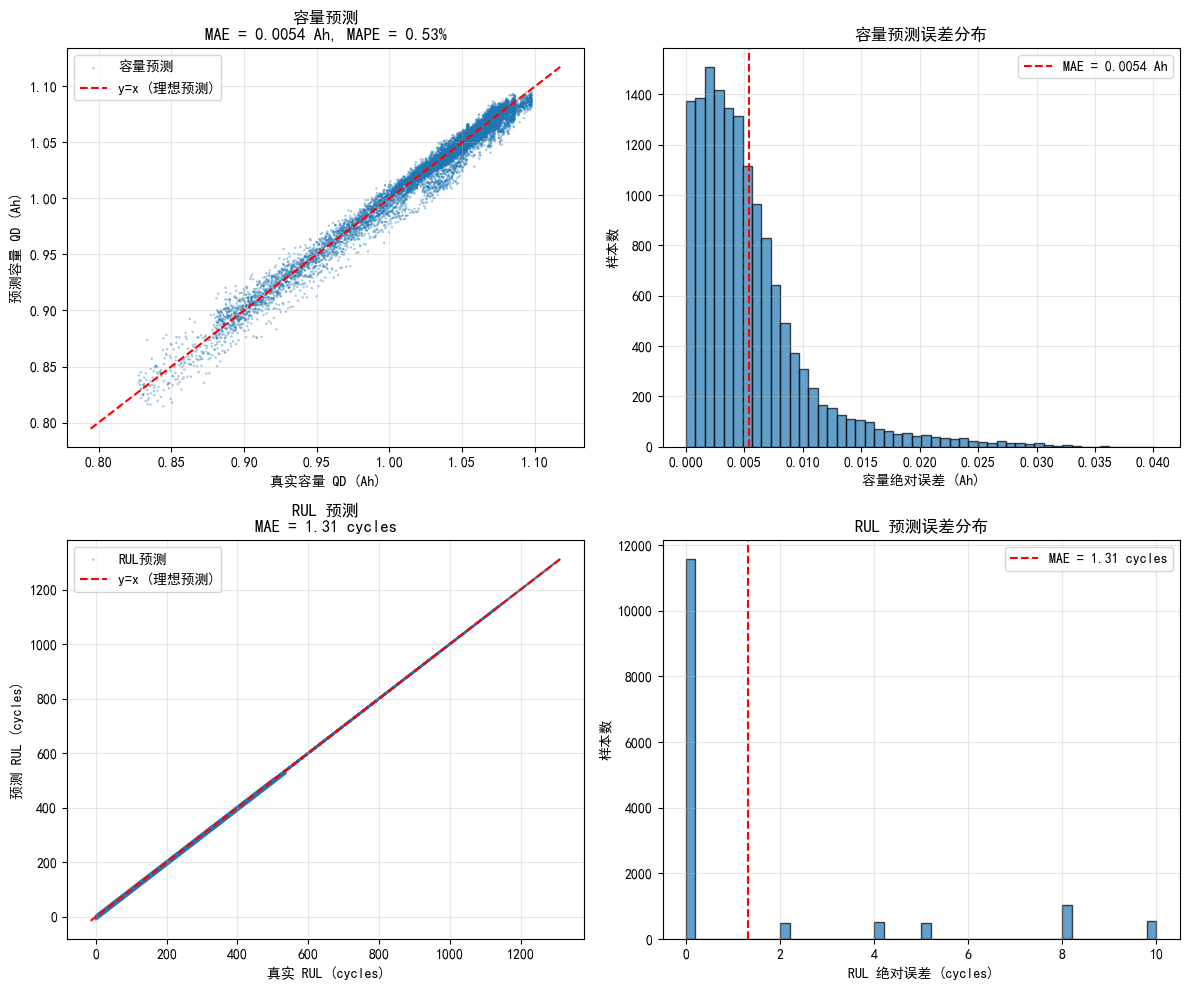

In [13]:
# ============================================================
# 可视化：容量预测 vs 真实值
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# ---------- 容量散点图 ----------
ax = axes[0, 0]
ax.scatter(cap_gt, cap_pred, alpha=0.4, s=3, edgecolors='none', label='容量预测')
lims_cap = [min(cap_gt.min(), cap_pred.min()) - 0.02,
            max(cap_gt.max(), cap_pred.max()) + 0.02]   # x,y轴共用范围
ax.plot(lims_cap, lims_cap, 'r--', label='y=x (理想预测)')
ax.set_xlabel('真实容量 QD_fixed (Ah)'); ax.set_ylabel('预测容量 QD_fixed (Ah)')
ax.set_title(f"容量预测\nMAE = {cap_abs_err.mean():.4f} Ah, MAPE = {cap_mape:.2f}%")
ax.legend()
ax.grid(True, alpha=0.3)

# ---------- 误差分布直方图 ----------
ax = axes[0, 1]
ax.hist(cap_abs_err, bins=50, edgecolor='k', alpha=0.7)
ax.axvline(cap_abs_err.mean(), color='r', linestyle='--',
           label=f"MAE = {cap_abs_err.mean():.4f} Ah")
ax.set_xlabel('容量绝对误差 (Ah)'); ax.set_ylabel('样本数')
ax.set_title('容量预测误差分布')
ax.legend()
ax.grid(True, alpha=0.3)

# ---------- RUL 散点图 / RUL 峰窝图----------
ax = axes[1, 0]
ax.scatter(rul_true_all, rul_pred_all, alpha=0.4, s=3, edgecolors='none', label='RUL预测')
lims_rul = [min(rul_true_all.min(), rul_pred_all.min()) - 5,
            max(rul_true_all.max(), rul_pred_all.max()) + 5]
ax.plot(lims_rul, lims_rul, 'r--', label='y=x (理想预测)')
ax.set_xlabel('真实 RUL (cycles)'); ax.set_ylabel('预测 RUL (cycles)')
ax.set_title(f"RUL 预测\nMAE = {rul_abs_err.mean():.2f} cycles")
ax.legend()
ax.grid(True, alpha=0.3)
# ax = axes[1, 0]
# hb = ax.hexbin(rul_true_all, rul_pred_all, gridsize=50,
#                cmap='Blues', mincnt=1, bins='log', alpha=0.85)
# lims_rul = [min(rul_true_all.min(), rul_pred_all.min()) - 5,
#             max(rul_true_all.max(), rul_pred_all.max()) + 5]
# ax.plot(lims_rul, lims_rul, 'r--', label='y=x (理想预测)')
# ax.set_xlabel('真实 RUL (cycles)'); ax.set_ylabel('预测 RUL (cycles)')
# ax.set_title(f"RUL 预测\nMAE = {rul_abs_err.mean():.2f} cycles")
# ax.legend()
# ax.grid(True, alpha=0.3)
# fig.colorbar(hb, ax=ax).set_label('log(样本数)')

# ---------- RUL 误差分布直方图 ----------
ax = axes[1, 1]
ax.hist(rul_abs_err, bins=50, edgecolor='k', alpha=0.7)
ax.axvline(rul_abs_err.mean(), color='r', linestyle='--',
           label=f"MAE = {rul_abs_err.mean():.2f} cycles")
ax.set_xlabel('RUL 绝对误差 (cycles)'); ax.set_ylabel('样本数')
ax.set_title('RUL 预测误差分布')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


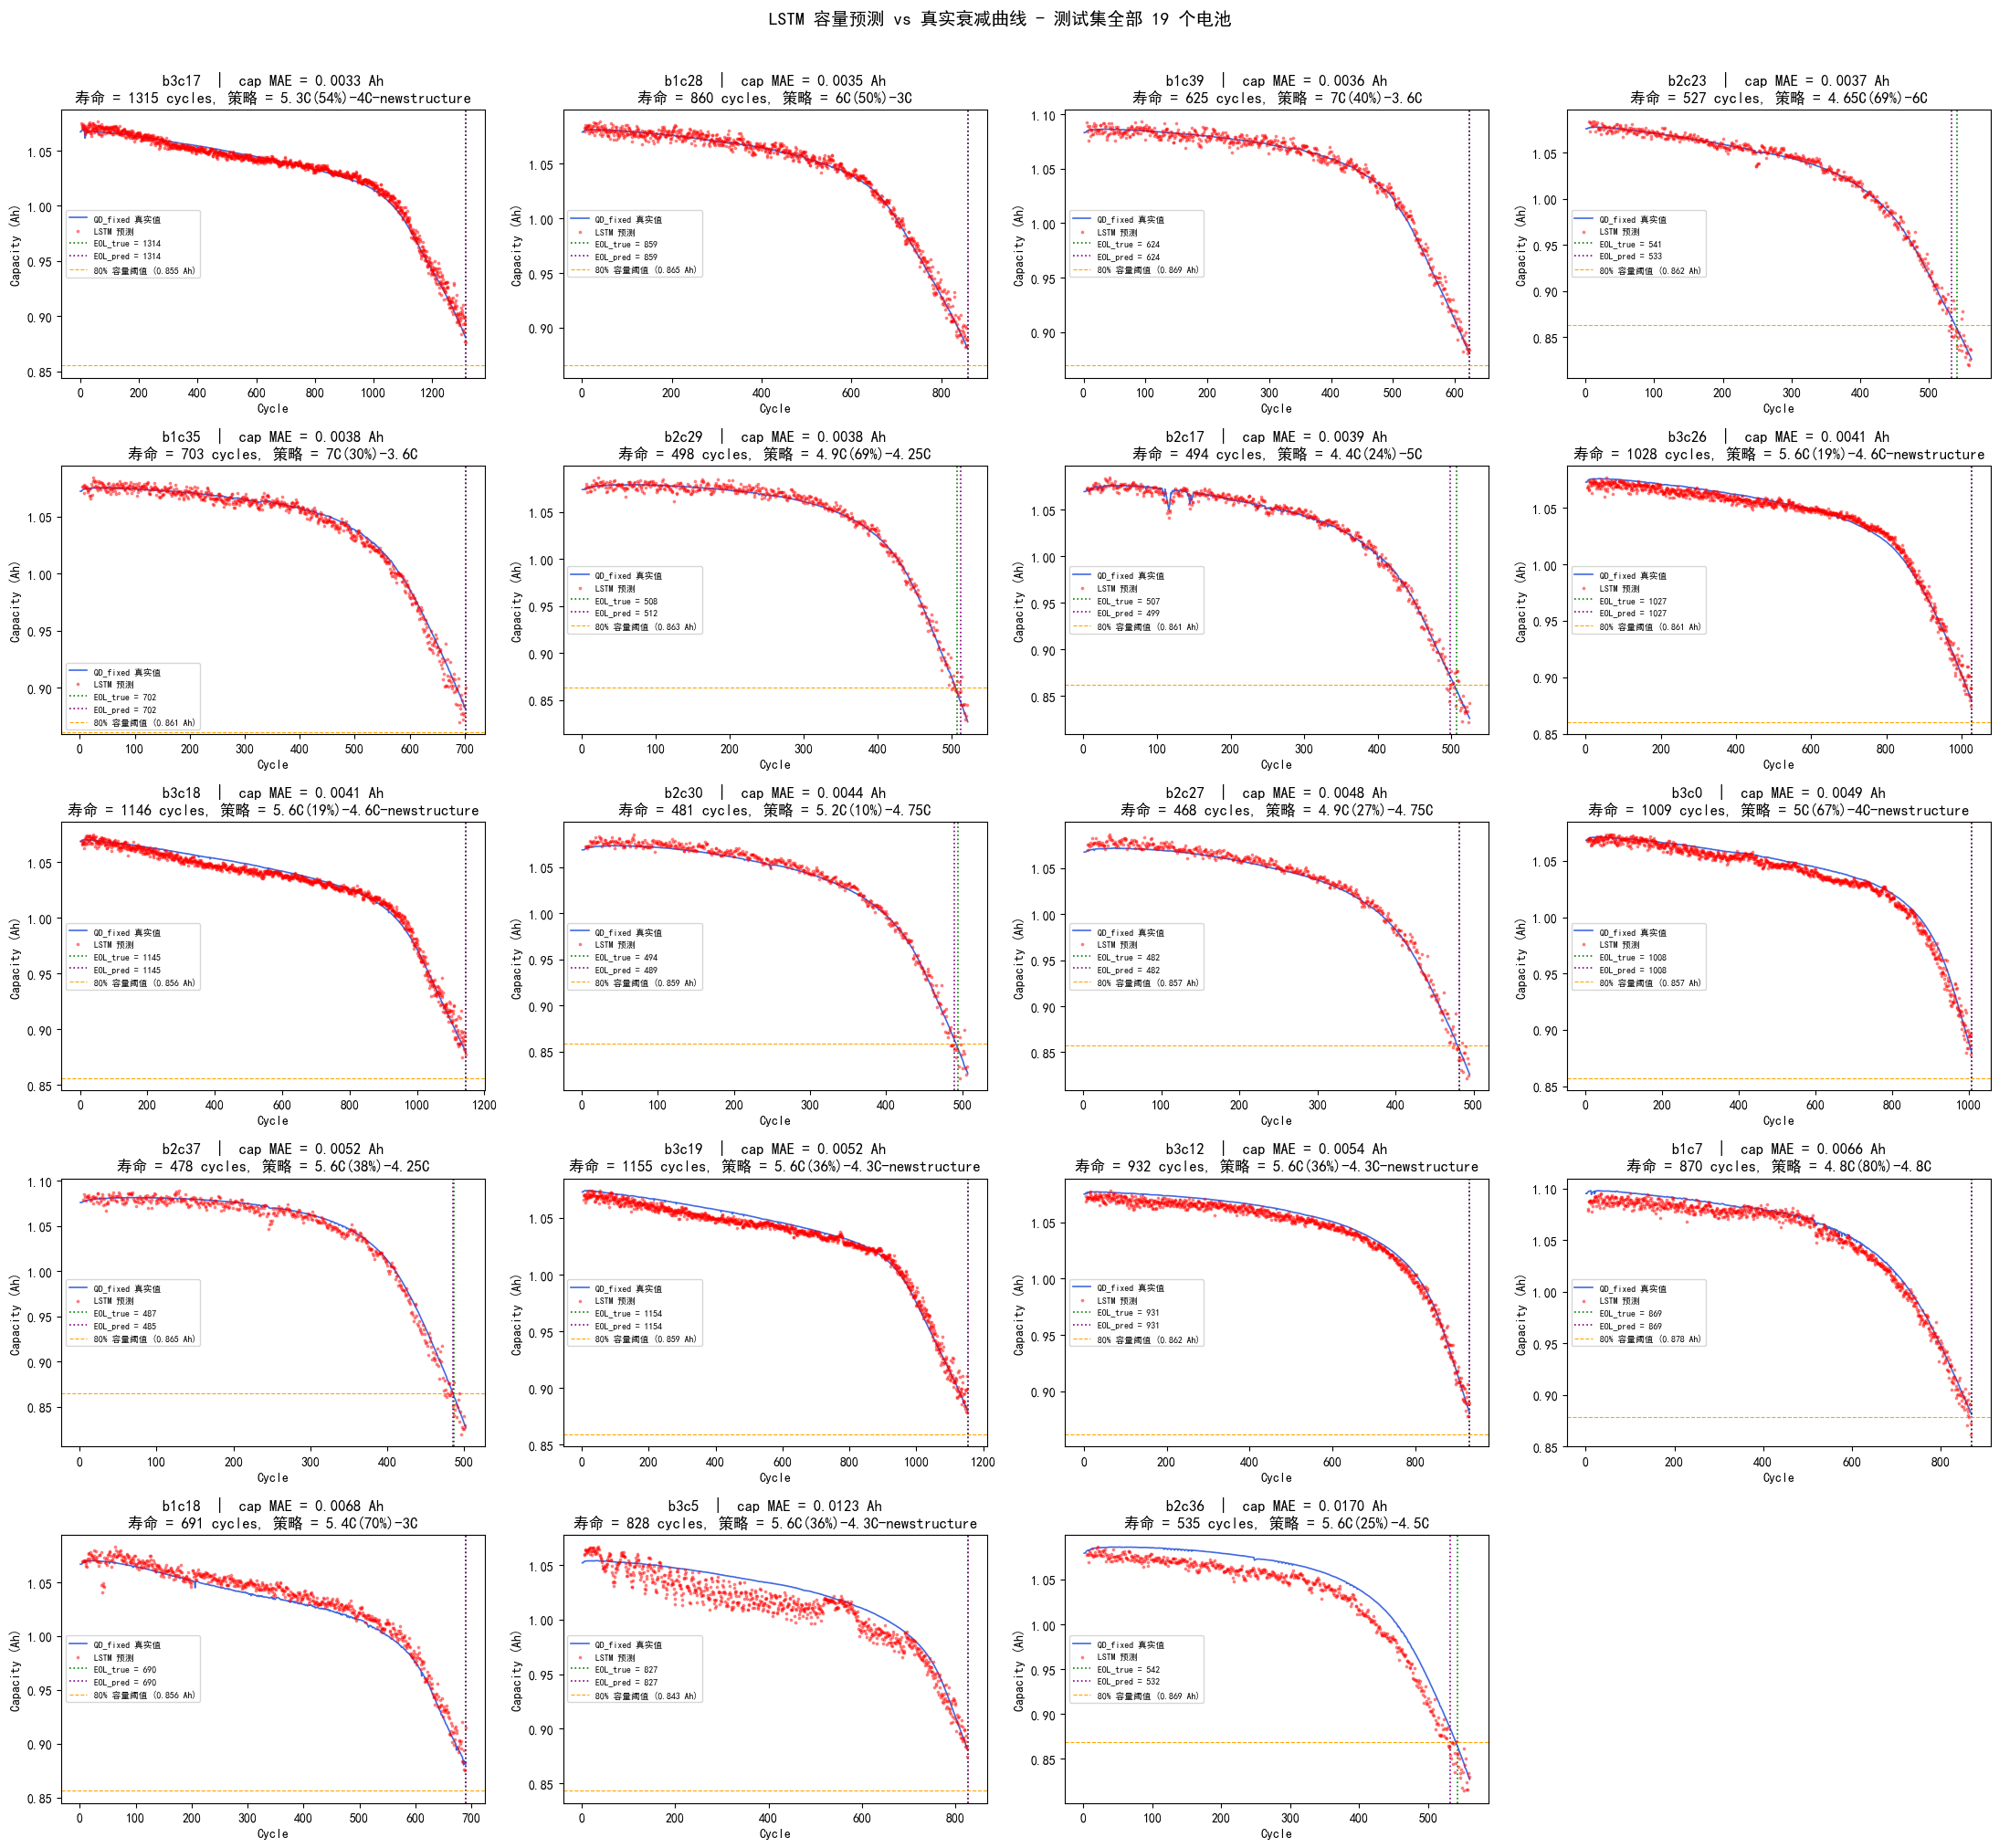

In [14]:
# ============================================================
# 测试集所有电池：容量衰减 + 预测曲线可视化
# ============================================================

# 按容量 MAE 排序
bat_cap_mae = {}
for r in results:
    name = r["name"]
    b = bat_dict[name]
    qd_fixed = np.asarray(b["summary"]["QD_fixed"], dtype=np.float64)
    cycle_nums = np.asarray(b["summary"]["cycle"], dtype=np.int64)
    cycle_to_idx = {int(cn): i for i, cn in enumerate(cycle_nums)}
    errs = []
    for i, lc in enumerate(r["last_cycles"]):
        idx = cycle_to_idx.get(lc)
        if idx is not None:
            errs.append(abs(r["cap_preds"][i] - qd_fixed[idx]))
    if errs:
        bat_cap_mae[name] = np.mean(errs)

sorted_names = sorted(bat_cap_mae, key=bat_cap_mae.get)
n_bats = len(sorted_names)

# 根据电池数量动态确定网格尺寸
n_cols = 4
n_rows = int(np.ceil(n_bats / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5.5, n_rows * 4))
axes = axes.flatten()

# EOL 阈值：每电池 80% × 自身最大容量（与 cell 10 的 RUL 评估一致）

for i, name in enumerate(sorted_names):
    ax = axes[i]
    b = bat_dict[name]
    qd_fixed = np.asarray(b["summary"]["QD_fixed"], dtype=np.float64)
    cycle_nums = np.asarray(b["summary"]["cycle"], dtype=np.int64)
    eol = (rul_meta[name][1] if name in rul_meta
           else float(b["summary"]["eol_cycle"]))
    
    # 真实容量曲线（使用实际 cycle 编号作为 x 轴）
    ax.plot(cycle_nums, qd_fixed, linewidth=1.2, color="royalblue", label="QD_fixed 真实值")
    
    # 预测值（每个窗口末尾）
    r_match = [r_ for r_ in results if r_["name"] == name][0]
    ax.scatter(r_match["last_cycles"], r_match["cap_preds"], alpha=0.4, s=3,
               color="red", label="LSTM 预测", zorder=5)
    
    # EOL 线
    ax.axvline(eol, color="green", linestyle=":", linewidth=1.2,
               label=f"EOL_true = {eol:.0f}")
    # 预测 EOL（预测曲线上首次低于阈值）
    if name in rul_meta:
        eol_pred_b = rul_meta[name][0]
        ax.axvline(eol_pred_b, color="purple", linestyle=":", linewidth=1.2,
                   label=f"EOL_pred = {eol_pred_b:.0f}")
    # 每电池 80% 容量阈值
    thr_b = 0.8 * float(qd_fixed.max())
    ax.axhline(thr_b, color="orange", linestyle="--", linewidth=0.8,
               label=f"80% 容量阈值 ({thr_b:.3f} Ah)")
    
    # 构建标题（避免在 f-string 中使用反斜杠）
    title_line1 = f"{name}  |  cap MAE = {bat_cap_mae[name]:.4f} Ah"
    life = int(float(np.asarray(b['cycle_life']).ravel()[0]))
    title_line2 = f"寿命 = {life} cycles, 策略 = {b['charge_policy']}"
    ax.set_title(title_line1 + "\n" + title_line2)
    ax.set_xlabel("Cycle")
    ax.set_ylabel("Capacity (Ah)")
    ax.legend(fontsize=7)

# 隐藏多余的空白子图
for j in range(n_bats, len(axes)):
    axes[j].set_visible(False)

plt.suptitle(f"LSTM 容量预测 vs 真实衰减曲线 - 测试集全部 {n_bats} 个电池", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()
